In [1]:
from pathlib import Path
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import clouddrift
from clouddrift.datasets import gdp1h

# --- Folders ---
DATA_DIR = Path("../data")
FIG_DIR  = Path("../figures")
RAW_DIR  = DATA_DIR / "raw"                       # inputs: RONI file + one-off GDP extract
OUT_DIR  = DATA_DIR / "01_data_prep_roni_gdp"     # outputs of this notebook
FIG_OUT  = FIG_DIR / "01_data_prep_roni_gdp"
for d in (RAW_DIR, OUT_DIR, FIG_OUT):
    d.mkdir(parents=True, exist_ok=True)

# --- Inputs / outputs ---
RONI_PATH        = RAW_DIR / "RONI.ascii.txt"
RAW_PATH         = RAW_DIR / "kuroshio_obs.parquet"         # extracted once from gdp1h()
CLEAN_PATH       = OUT_DIR / "kuroshio_obs_clean.parquet"
PHASE_PATH       = OUT_DIR / "roni_phase.csv"
META_PATH        = RAW_DIR / "gdp_metadata.json"            # ds.attrs + flg_sst attrs, saved at extraction
PHASE_TABLE_PATH = OUT_DIR / "enso_phase_support.csv"
SUMMARY_PATH     = OUT_DIR / "data_prep_summary.json"
RONI_FIG_PATH    = FIG_OUT / "roni_enso_phases.png"

# --- Study region (Kuroshio box) and period ---
LON_MIN, LON_MAX, LAT_MIN, LAT_MAX = 115, 145, 15, 40
STUDY = ("1990-03", "2022-10")   # months covered by in-box drifter data

# --- ENSO definition (NOAA CPC) ---
ENSO_THRESH, MIN_SEASONS = 0.5, 5

# --- SST quality: keep only flag 5 (estimate and uncertainty in range) ---
SST_GOOD_FLAG = 5

summary = {}   # every number quoted in Section 3 goes in here

### RONI DATASET

In [2]:
# --- Load RONI ---
inputFile = pd.read_csv(RONI_PATH, sep=r"\s+")

In [3]:
# Each 3-month season -> date of its centre month (DJF 1950 -> 1950-01-01)
# reformatting for drifter data comparison

seas_to_month = {"DJF":1,"JFM":2,"FMA":3,"MAM":4,"AMJ":5,"MJJ":6,
                 "JJA":7,"JAS":8,"ASO":9,"SON":10,"OND":11,"NDJ":12}
inputFile["time"] = pd.to_datetime(dict(year=inputFile["YR"],
                                  month=inputFile["SEAS"].map(seas_to_month), day=1))

roni = inputFile.set_index("time")["ANOM"].rename("roni")

In [4]:
roni.to_frame()

,roni
time,
1950-01-01,-1.19
1950-02-01,-1.08
1950-03-01,-0.96
1950-04-01,-1.00
1950-05-01,-0.99
...,...
2026-04-01,-0.04
2026-05-01,0.49
2026-06-01,0.97


### ENSO phases

Months are classed as El Niño (RONI ≥ +0.5 °C) or La Niña (RONI ≤ −0.5 °C) only when the threshold holds for at least five consecutive overlapping 3-month seasons, following NOAA CPC’s historical episode definition (NWS PNS 26-05). All other months are Neutral. Isolated months that cross the threshold are therefore not counted as events. Each observation takes the phase of its own month (no lag).

In [5]:
# --- ENSO phase: NOAA CPC episode definition ---
# El Niño (La Niña) = RONI >= +0.5 (<= -0.5) for at least 5 consecutive overlapping seasons
def persistent(mask, k=MIN_SEASONS):
    """True only where the condition holds for a run of at least k consecutive months."""
    run_id = (mask != mask.shift()).cumsum()                     # label each unbroken run
    run_len = mask.groupby(run_id).transform("size")             # length of the run each month sits in
    return mask & (run_len >= k)

el_nino = persistent(roni >= ENSO_THRESH)
la_nina = persistent(roni <= -ENSO_THRESH)

roni_phase = pd.Series(
    np.select([la_nina, el_nino], ["La Niña", "El Niño"], default="Neutral"),
    index=roni.index, name="enso")

In [6]:
roni_phase.to_csv(PHASE_PATH)

In [7]:
start, end = STUDY
phase_months = roni_phase[start:end].value_counts()
print(phase_months)
print(len(roni_phase[start:end]), "months of overlap")

enso
Neutral    179
La Niña    124
El Niño     89
Name: count, dtype: int64
392 months of overlap


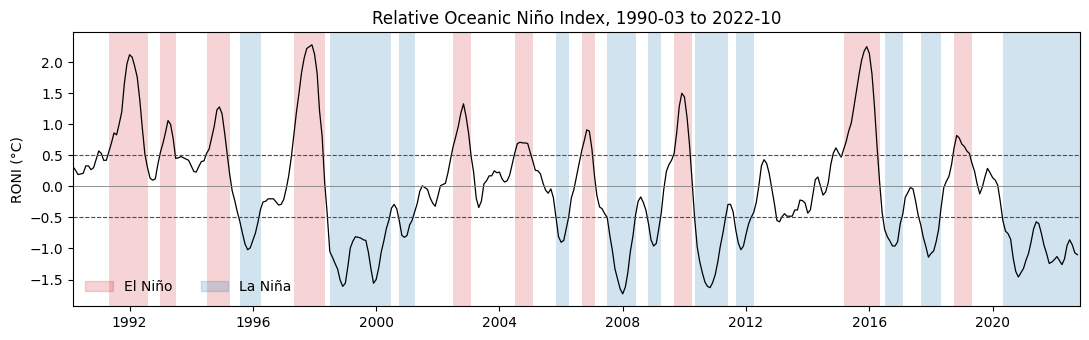

In [8]:
# --- RONI over the study period, ENSO phases shaded ---
r  = roni[start:end]
ph = roni_phase[start:end]
next_month = r.index + pd.offsets.MonthBegin(1)               # each month spans [month, next month)

fig, ax = plt.subplots(figsize=(11, 3.5))
for phase, colour in [("El Niño", "tab:red"), ("La Niña", "tab:blue")]:
    on = (ph == phase).to_numpy()
    run_id = np.cumsum(np.r_[True, on[1:] != on[:-1]])           # label each unbroken run
    for k in np.unique(run_id[on]):
        idx = np.flatnonzero(run_id == k)
        ax.axvspan(r.index[idx[0]], next_month[idx[-1]], color=colour, alpha=0.2, lw=0)

ax.plot(r.index, r.values, color="k", lw=0.9)
ax.axhline(0, color="0.5", lw=0.6)
for y in (ENSO_THRESH, -ENSO_THRESH):
    ax.axhline(y, color="0.3", ls="--", lw=0.8)

ax.set_xlim(r.index[0], next_month[-1])
ax.set_ylabel("RONI (°C)")
ax.set_title(f"Relative Oceanic Niño Index, {start} to {end}")
ax.legend(handles=[Patch(color="tab:red", alpha=0.2, label="El Niño"),
                   Patch(color="tab:blue", alpha=0.2, label="La Niña")],
          loc="lower left", frameon=False, ncol=2)
fig.tight_layout()
fig.savefig(RONI_FIG_PATH, dpi=300, bbox_inches="tight")
plt.show()

### DRIFTERS DATASET

In [9]:
if not RAW_PATH.exists():                     # extract once, then reload from parquet
    ds = gdp1h()                              # full GDP hourly dataset: only loaded when extracting

    # --- Save dataset metadata so later runs don't need to load ds ---
    meta = {"clouddrift_version": clouddrift.__version__,
            "ds_attrs":      dict(ds.attrs),
            "flg_sst_attrs": dict(ds["flg_sst"].attrs)}
    with open(META_PATH, "w") as f:
        json.dump(meta, f, indent=2, default=str)

    # Per-drifter values repeated rowsize times to line up with observations
    rowsize = ds["rowsize"].values
    obs_id        = np.repeat(ds["id"].values, rowsize)
    obs_lost_date = np.repeat(ds["drogue_lost_date"].values, rowsize)
    obs_end_date  = np.repeat(ds["end_date"].values, rowsize)

    lon, lat = ds["lon"].values, ds["lat"].values
    box = (lon >= LON_MIN) & (lon <= LON_MAX) & (lat >= LAT_MIN) & (lat <= LAT_MAX)

    # --- Build a table of just the in-box observations ---
    df = pd.DataFrame({
        "id":               obs_id[box],                        # drifter id
        "time":             ds["time"].values[box],             # hourly timestamp
        "lon":              lon[box],                           # longitude
        "lat":              lat[box],                           # latitude
        "ve":               ds["ve"].values[box],               # eastward velocity (m/s)
        "vn":               ds["vn"].values[box],               # northward velocity (m/s)
        "err_ve":           ds["err_ve"].values[box],           # eastward velocity uncertainty (m/s)
        "err_vn":           ds["err_vn"].values[box],           # northward velocity uncertainty (m/s)
        "sst":              ds["sst"].values[box],              # sea-surface temperature
        "flg_sst":          ds["flg_sst"].values[box],          # SST quality flag
        "drogue_status":    ds["drogue_status"].values[box],    # drogued or not (per hour)
        "drogue_lost_date": obs_lost_date[box],                 # per-drifter drogue loss date
        "end_date":         obs_end_date[box],                  # per-drifter end of record
    })

    # --- Free the big global arrays, we only need df now ---
    del lon, lat, obs_id, obs_lost_date, obs_end_date, box, ds

    print(len(df), "observations,", df["id"].nunique(), "drifters")
    df.to_parquet(RAW_PATH)

In [10]:
# --- Dataset metadata (saved at extraction) ---
gdp_meta = json.loads(META_PATH.read_text())
print("clouddrift used for extraction:", gdp_meta["clouddrift_version"], "| installed:", clouddrift.__version__)
print(gdp_meta["ds_attrs"])          # look for version / date_created / date_modified

clouddrift used for extraction: 0.48.1 | installed: 0.48.1
{'Conventions': 'CF-1.6', 'acknowledgement': 'Elipot, Shane; Sykulski, Adam; Lumpkin, Rick; Centurioni, Luca; Pazos, Mayra (2022). Hourly location, current velocity, and temperature collected from Global Drifter Program drifters world-wide. [indicate subset used]. NOAA National Centers for Environmental Information. Dataset. https://doi.org/10.25921/x46c-3620. Accessed [date]. Elipot et al. (2022): A Dataset of Hourly Sea Surface Temperature From Drifting Buoys, Scientific Data, 9, 567, https://dx.doi.org/10.1038/s41597-022-01670-2. Elipot et al. (2016): A global surface drifter dataset at hourly resolution, J. Geophys. Res.-Oceans, 121, https://dx.doi.org/10.1002/2016JC011716.', 'contributor_name': 'NOAA Global Drifter Program', 'contributor_role': 'Data Acquisition Center', 'date_created': '2024-07-30T19:02:16.200531', 'doi': '10.25921/x46c-3620', 'history': 'version 2.01.1. Metadata from dirall.dat and deplog.dat', 'institut

In [11]:
# --- Load region observation data ---
df = pd.read_parquet(RAW_PATH)

In [12]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 4623446 entries, 0 to 4623445
Data columns (total 13 columns):
 #   Column            Dtype         
---  ------            -----         
 0   id                int64         
 1   time              datetime64[ns]
 2   lon               float64       
 3   lat               float64       
 4   ve                float32       
 5   vn                float32       
 6   err_ve            float32       
 7   err_vn            float32       
 8   sst               float32       
 9   flg_sst           int8          
 10  drogue_status     bool          
 11  drogue_lost_date  datetime64[ns]
 12  end_date          datetime64[ns]
dtypes: bool(1), datetime64[ns](3), float32(5), float64(2), int64(1), int8(1)
memory usage: 308.6 MB


,id,time,lon,lat,ve,vn,err_ve,err_vn,sst,flg_sst,drogue_lost_date,end_date
count,4.623446e+06,4623446,4.623446e+06,4.623446e+06,4.623446e+06,4.614785e+06,4.347198e+06,4.347145e+06,4.405541e+06,4.623446e+06,4617583,4539578
mean,7.809856e+13,2012-11-16 18:44:47.306221056,1.325997e+02,2.489803e+01,-1.405953e-03,3.822276e-02,5.531375e-02,4.078855e-02,2.997542e+02,4.757985e+00,2011-07-29 01:55:23.944410880,2013-07-17 01:42:48.201184768
min,4.888000e+03,1990-03-11 11:00:00,1.150000e+02,1.500000e+01,-2.369572e+00,-2.278600e+00,2.430557e-06,2.430557e-06,-9.798068e+02,0.000000e+00,1970-01-01 00:00:00,1990-11-04 00:00:00
25%,5.990300e+04,2009-02-13 18:00:00,1.265290e+02,1.976139e+01,-2.096986e-01,-1.495000e-01,1.376650e-02,1.370031e-02,2.965830e+02,5.000000e+00,2008-07-06 00:00:00,2009-10-02 00:00:00
50%,1.075870e+05,2012-07-22 02:00:00,1.328334e+02,2.374053e+01,-1.790000e-02,2.650000e-02,3.190000e-02,2.360000e-02,2.999850e+02,5.000000e+00,2012-05-14 00:00:00,2012-11-03 00:00:00
75%,3.002341e+14,2017-01-19 10:00:00,1.391201e+02,2.933222e+01,1.821000e-01,2.108131e-01,7.050000e-02,5.040000e-02,3.020220e+02,5.000000e+00,2016-04-25 00:00:00,2017-12-03 00:00:00
max,3.005341e+14,2022-10-31 00:00:00,1.450000e+02,4.000000e+01,2.576450e+00,2.765326e+00,3.051200e+00,4.355300e+00,2.697633e+03,5.000000e+00,2023-05-13 00:00:00,2023-06-09 00:00:00
std,1.317310e+14,NaN,7.648264e+00,6.468672e+00,3.355585e-01,3.117717e-01,6.668352e-02,4.713312e-02,2.828013e+01,1.066814e+00,NaN,NaN


In [13]:
# --- Domain summary (runs on every load; numbers for Section 3.2) ---
print(f"observations: {len(df):,}")
print(f"drifters:     {df['id'].nunique():,}")
print(f"first obs:    {df['time'].min():%Y-%m-%d}")
print(f"last obs:     {df['time'].max():%Y-%m-%d}")
print(f"median obs:   {df['time'].median():%Y-%m-%d}")

summary["total_obs"]      = int(len(df))
summary["total_drifters"] = int(df["id"].nunique())
summary["first_obs"]      = f"{df['time'].min():%Y-%m-%d}"
summary["last_obs"]       = f"{df['time'].max():%Y-%m-%d}"
summary["median_obs"]     = f"{df['time'].median():%Y-%m-%d}"

observations: 4,623,446
drifters:     1,531
first obs:    1990-03-11
last obs:     2022-10-31
median obs:   2012-07-22


### SST filtering

In [14]:
print(gdp_meta["flg_sst_attrs"])                 # flag_values / flag_meanings
flag_counts = df["flg_sst"].value_counts(dropna=False).sort_index()
print(flag_counts)
summary["sst_flag_counts"] = {str(k): int(v) for k, v in flag_counts.items()}

{'flag_meanings': 'no-estimate, no-uncertainty-estimate, estimate-not-in-range-uncertainty-not-in-range, estimate-not-in-range-uncertainty-in-range estimate-in-range-uncertainty-not-in-range, estimate-in-range-uncertainty-in-range', 'flag_values': '0, 1, 2, 3, 4, 5', 'long_name': 'Fitted sea water temperature quality flag', 'units': '-'}
flg_sst
0     217896
1          3
2       8920
3       1146
4        399
5    4395082
Name: count, dtype: int64


In [15]:
# --- Keep SST only where estimate and uncertainty are both in range (flag 5) ---
# SST stays in Kelvin here: notebooks 02, 03 and 05 convert to °C themselves.
sst_bad = df["flg_sst"] != SST_GOOD_FLAG
print(f"SST values set to NaN (flag != {SST_GOOD_FLAG}): {(sst_bad & df['sst'].notna()).sum():,}")
summary["sst_set_to_nan"] = int((sst_bad & df["sst"].notna()).sum())
df.loc[sst_bad, "sst"] = np.nan

summary["valid_sst_obs"]  = int(df["sst"].notna().sum())
print(f"valid SST observations: {summary['valid_sst_obs']:,}")

SST values set to NaN (flag != 5): 10,459
valid SST observations: 4,395,082


Data check (Kuroshio box, 115–145°E, 15–40°N). The extracted subset contains 4,623,446 hourly observations, with all positions inside the box. In-box sampling begins in March 1990 rather than at the start of the GDP record (October 1987), and the median observation date is mid-2012. Half the data therefore comes from the last decade, which will weight any time-based composites (including ENSO phases) towards recent events. SST is stored in Kelvin and quality-controlled with the dataset's own flag (flg_sst): 217,896 observations have no SST estimate (flag 0), and a further 10,468 (about 0.2%) are excluded because their estimate or its uncertainty falls outside the accepted range (flags 1–4). Only flag-5 values, where both the estimate and its uncertainty are within range, are kept, leaving 4,395,082 valid SST observations from 1,486 drifters. SST is kept in Kelvin here and converted to °C in the analysis notebooks

### Drogue status checks

The hourly drogue flag is compared with each drifter's recorded drogue loss date before it is used to select velocities.

In [16]:
df["drogue_status"].value_counts(dropna=False)

drogue_status
False    2486448
True     2136998
Name: count, dtype: int64

In [17]:
# --- Drogue cross-check ---
# drogue_status is recorded per hour; drogue_lost_date is recorded once per drifter.
# Check that the two agree before using them to select drogued velocities.
t    = pd.to_datetime(df["time"])               # observation time
lost = pd.to_datetime(df["drogue_lost_date"])   # when this drifter's drogue came off

has_lost    = lost.notna()                      # drifters with a recorded loss date
before_loss = has_lost & (t < lost)             # date says: drogue still attached
after_loss  = has_lost & (t >= lost)            # date says: drogue gone

# Disagreements between the hourly flag and the loss date
flag_drogued_after_loss = df["drogue_status"] & after_loss
flag_undrogued_before   = ~df["drogue_status"] & before_loss

lost_1970 = df.loc[lost == pd.Timestamp("1970-01-01"), "id"].nunique()

print(f"no lost date recorded:          {(~has_lost).sum():,} obs, {df.loc[~has_lost, 'id'].nunique()} drifters")
print(f"flag drogued but after loss:    {flag_drogued_after_loss.sum():,}")
print(f"flag undrogued but before loss: {flag_undrogued_before.sum():,}")
print(f"drogue_lost_date of 1970-01-01: {lost_1970} drifters")

assert flag_drogued_after_loss.sum() == 14
assert flag_undrogued_before.sum() == 0

summary["no_lost_date_obs"]           = int((~has_lost).sum())
summary["no_lost_date_drifters"]      = int(df.loc[~has_lost, "id"].nunique())
summary["flag_drogued_after_loss"]    = int(flag_drogued_after_loss.sum())
summary["flag_undrogued_before_loss"] = int(flag_undrogued_before.sum())
summary["lost_date_1970_drifters"]    = int(lost_1970)

no lost date recorded:          5,863 obs, 7 drifters
flag drogued but after loss:    14
flag undrogued but before loss: 0
drogue_lost_date of 1970-01-01: 45 drifters


In [18]:
# --- Final drogue selection for velocity ---
# Drogued = the hourly flag says drogued AND the hour is not after a recorded drogue loss.
# Drifters with no loss date are flagged drogued throughout, so they are kept.
df["drogued"] = df["drogue_status"] & ~(has_lost & (t >= lost))

print(f"drogued (flag only):         {df['drogue_status'].sum():,}")
print(f"drogued (flag + date agree): {df['drogued'].sum():,}")

# The per-drifter date columns are no longer needed downstream
df = df.drop(columns=["drogue_lost_date", "end_date"])

summary["drogued_flag_only"]     = int(df["drogue_status"].sum())
summary["drogued_flag_and_date"] = int(df["drogued"].sum())

# Velocity needs both components: drogued hours with a missing vn are set to undrogued,
# so the saved parquet's drogued column already excludes them
assert not (df["drogued"] & df["ve"].isna()).any()      # ve is never missing on drogued hours
vn_missing = df["drogued"] & df["vn"].isna()
print(f"drogued hours with missing vn (set to undrogued): {vn_missing.sum():,}")
summary["drogued_one_velocity_missing_removed"] = int(vn_missing.sum())
df.loc[vn_missing, "drogued"] = False

# Drogued only: use for current velocity (ve, vn)
df_drogued = df[df["drogued"]].copy()

drogued (flag only):         2,136,998
drogued (flag + date agree): 2,136,984
drogued hours with missing vn (set to undrogued): 1,193


Drogue status was cross-checked against each drifter’s recorded drogue loss date. The two agree for all but 14 hourly observations, flagged drogued after the recorded loss, which were excluded. Seven drifters with no loss date are flagged drogued throughout and were retained. For 45 drifters the recorded loss date (1 January 1970) falls before the start of the GDP record; their hourly flags show them as undrogued throughout. This leaves 2,136,984 drogued hours. A further 1,193 drogued hours, all Argos-tracked, have a valid ve but a missing vn and are excluded from the velocity analysis (they remain in the SST analysis), leaving 2,135,791 drogued hours from 1,177 drifters.

### Velocity uncertainty check

This check decides whether drogued velocities need filtering beyond the drogue criteria. We compare the typical uncertainty with the natural variability of the current, separately for each tracking system. Tracking is inferred from the drifter id: Iridium drifters have 15-digit ids and are GPS-located. If the uncertainty is small relative to the variability, it will average out in a cell mean and no filter is needed.

In [19]:
dv  = df[df["drogued"]]
err = np.hypot(dv["err_ve"], dv["err_vn"])                # combined velocity uncertainty (m/s)
tracking = np.where(dv["id"] >= 1e14, "GPS (Iridium)", "Argos")   # 15-digit Iridium ids are GPS-located

print(f"non-finite uncertainties: {(~np.isfinite(err)).sum():,}")
print(err.groupby(tracking).describe(percentiles=[.5, .9, .99]).round(3))
print(f"velocity std (drogued): ve {dv['ve'].std():.3f}, vn {dv['vn'].std():.3f} m/s")

non-finite uncertainties: 79,881


                   count   mean    std    min    50%    90%    99%    max
Argos          1283176.0  0.092  0.079  0.001  0.070  0.181  0.390  4.373
GPS (Iridium)   772734.0  0.022  0.021  0.000  0.019  0.026  0.102  0.687
velocity std (drogued): ve 0.318, vn 0.305 m/s


In [20]:
nf = ~np.isfinite(err)
print(f"velocity finite where uncertainty missing: {np.isfinite(dv.loc[nf, 've']).mean():.1%}")
print(pd.Series(tracking[nf]).value_counts())

velocity finite where uncertainty missing: 100.0%
Argos            78129
GPS (Iridium)     1752
Name: count, dtype: int64


The median uncertainty is 0.019 m/s for GPS-tracked drifters and 0.070 m/s for Argos-tracked drifters, against a velocity variability of about 0.31 m/s. Uncertainty is therefore small next to the real variability of the current, and as random error it averages out in a cell mean. Filtering on it would mainly remove early, Argos-era hours, thinning the parts of the record that are already sparse. No velocity filter is applied.

3.7% of drogued hours (98% Argos) have no uncertainty estimate but do have a valid velocity, and are retained. No uncertainty filter is applied. The only further removal is 1,193 drogued hours with a valid ve but a missing vn, which leaves 2,135,791 drogued hours (46.2% of all observations) from 1,177 drifters for velocity.

In [21]:
sst_ok = df["sst"].notna()
print(f"SST analysis:      {sst_ok.sum():,} observations with valid SST "
      f"from {df.loc[sst_ok, 'id'].nunique():,} drifters")
print(f"Velocity analysis: {len(df_drogued):,} drogued observations "
      f"({len(df_drogued) / len(df):.1%}) from {df_drogued['id'].nunique():,} drifters")

summary["valid_sst_drifters"]        = int(df.loc[sst_ok, "id"].nunique())
summary["drogued_velocity_obs"]      = int(len(df_drogued))
summary["drogued_velocity_drifters"] = int(df_drogued["id"].nunique())

SST analysis:      4,395,082 observations with valid SST from 1,486 drifters
Velocity analysis: 2,135,791 drogued observations (46.2%) from 1,177 drifters


### RONI Tagging

In [22]:
# --- Tag every observation with its month's RONI value and phase ---
# Round each timestamp down to the 1st of its month to match the RONI index
month = pd.to_datetime(df["time"]).dt.to_period("M").dt.to_timestamp()
df["roni"] = month.map(roni)          # numeric RONI value
df["enso"] = month.map(roni_phase)    # "El Niño" / "La Niña" / "Neutral"
assert df["roni"].notna().all()       # every month 1990–2022 is in RONI, so none missing

# --- Recreate the drogued subset so it carries roni/enso too ---
# Uses the cross-checked drogue column (flag + loss date agree, vn present)
df_drogued = df[df["drogued"]].copy()

# --- How much data each ENSO phase has ---
def phase_summary(d, value_col):
    s = d.groupby("enso").agg(n_obs=(value_col, "count"),     # non-missing values
                              n_drifters=("id", "nunique"))   # distinct drifters
    s["share_obs"] = (s["n_obs"] / s["n_obs"].sum()).round(3)
    return s

vel_support = phase_summary(df_drogued, "ve")
sst_support = phase_summary(df, "sst")
print("Velocity (drogued):\n", vel_support, "\n")
print("SST (all drifters):\n", sst_support)

Velocity (drogued):
            n_obs  n_drifters  share_obs
enso                                   
El Niño   252229         212      0.118
La Niña   836252         501      0.392
Neutral  1047310         743      0.490 

SST (all drifters):
            n_obs  n_drifters  share_obs
enso                                   
El Niño   725198         381      0.165
La Niña  1677973         778      0.382
Neutral  1991911        1038      0.453


In [23]:
# --- ENSO phase support table (Section 3) ---
phase_table = pd.concat([
    phase_months.rename("n_months"),
    (phase_months / phase_months.sum()).round(3).rename("share_months"),
    vel_support.add_prefix("vel_"),
    sst_support.add_prefix("sst_"),
], axis=1).reindex(["El Niño", "Neutral", "La Niña"])
phase_table.index.name = "enso"

phase_table.to_csv(PHASE_TABLE_PATH)
phase_table

,n_months,share_months,vel_n_obs,vel_n_drifters,vel_share_obs,sst_n_obs,sst_n_drifters,sst_share_obs
enso,,,,,,,,
El Niño,89,0.227,252229,212,0.118,725198,381,0.165
Neutral,179,0.457,1047310,743,0.490,1991911,1038,0.453
La Niña,124,0.316,836252,501,0.392,1677973,778,0.382


In [24]:
# Cleaned + RONI-tagged Kuroshio subset (all drifters; drogue filter applied in analysis)
df.to_parquet(CLEAN_PATH)

In [25]:
# --- Key numbers for Section 3 ---
SUMMARY_PATH.write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "total_obs": 4623446,
  "total_drifters": 1531,
  "first_obs": "1990-03-11",
  "last_obs": "2022-10-31",
  "median_obs": "2012-07-22",
  "sst_flag_counts": {
    "0": 217896,
    "1": 3,
    "2": 8920,
    "3": 1146,
    "4": 399,
    "5": 4395082
  },
  "sst_set_to_nan": 10459,
  "valid_sst_obs": 4395082,
  "no_lost_date_obs": 5863,
  "no_lost_date_drifters": 7,
  "flag_drogued_after_loss": 14,
  "flag_undrogued_before_loss": 0,
  "lost_date_1970_drifters": 45,
  "drogued_flag_only": 2136998,
  "drogued_flag_and_date": 2136984,
  "drogued_one_velocity_missing_removed": 1193,
  "valid_sst_drifters": 1486,
  "drogued_velocity_obs": 2135791,
  "drogued_velocity_drifters": 1177
}
